In [6]:
import numpy as np
import matplotlib.pyplot as plt

import pywt
import numpy as np
import matplotlib.pyplot as plt

import jlinops

In [25]:
image = jlinops.cameraman()
#image = np.random.rand(256, 256)
image += 0.1*np.random.normal(size=image.shape)

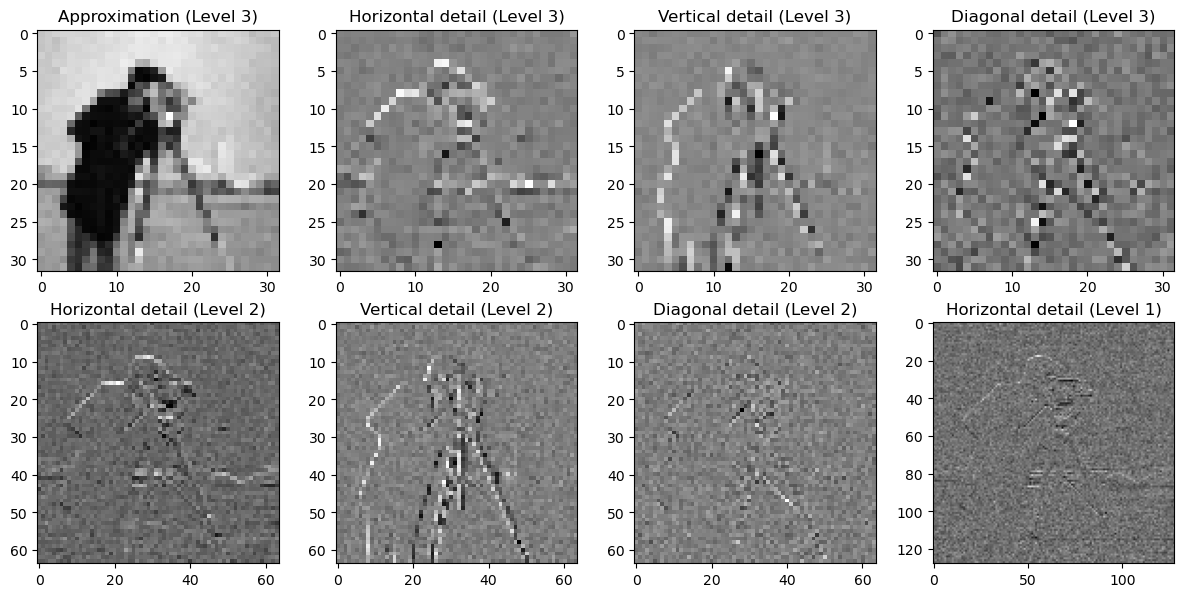

In [26]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(image, 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


In [10]:

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(image, 'haar', level=3)

# Perform the inverse wavelet transform (reconstruction) from the coefficients
reconstructed_image = pywt.waverec2(coeffs, 'haar')

# Compute the norm of the difference between the original and reconstructed images
reconstruction_error = np.linalg.norm(image - reconstructed_image)

# Print the reconstruction error
print(f"Reconstruction error (should be very close to 0): {reconstruction_error:.10f}")


Reconstruction error (should be very close to 0): 0.0000000000


In [15]:
len(coeffs)

4

(array([147.,  28.,  44.,  35.,  38., 121., 163., 189., 227.,  32.]),
 array([0.12215962, 0.74762994, 1.37310026, 1.99857058, 2.6240409 ,
        3.24951122, 3.87498154, 4.50045186, 5.12592218, 5.7513925 ,
        6.37686282]),
 <BarContainer object of 10 artists>)

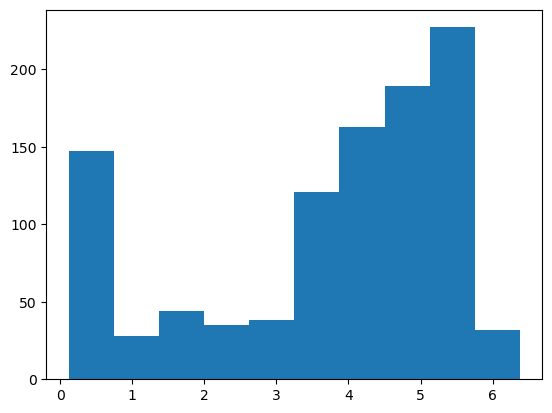

In [27]:
plt.hist(coeffs[0].flatten())

(array([  2.,   2.,   9.,  38., 369., 529.,  45.,  14.,   9.,   7.]),
 array([-1.85232596, -1.48675819, -1.12119042, -0.75562264, -0.39005487,
        -0.0244871 ,  0.34108067,  0.70664844,  1.07221621,  1.43778398,
         1.80335175]),
 <BarContainer object of 10 artists>)

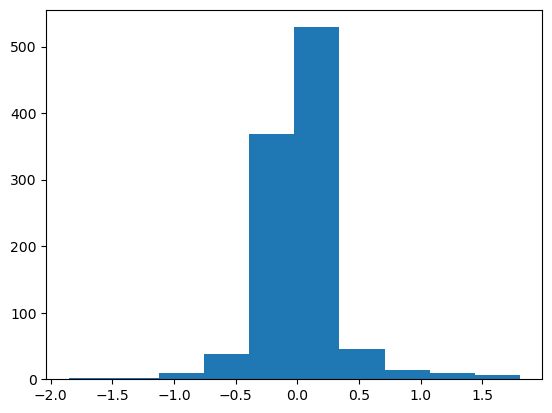

In [28]:
plt.hist(coeffs[1][0].flatten())

(array([  5.,   7.,  12.,  26., 142., 750.,  37.,  26.,  12.,   7.]),
 array([-2.44660786, -1.98596192, -1.52531598, -1.06467003, -0.60402409,
        -0.14337815,  0.31726779,  0.77791373,  1.23855967,  1.69920562,
         2.15985156]),
 <BarContainer object of 10 artists>)

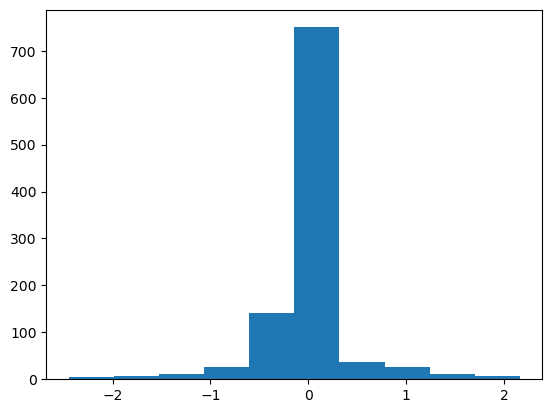

In [29]:
plt.hist(coeffs[1][1].flatten())

(array([  8.,  12.,  26., 131., 559., 226.,  39.,   9.,  12.,   2.]),
 array([-0.94745813, -0.74222717, -0.53699621, -0.33176525, -0.12653428,
         0.07869668,  0.28392764,  0.4891586 ,  0.69438956,  0.89962052,
         1.10485149]),
 <BarContainer object of 10 artists>)

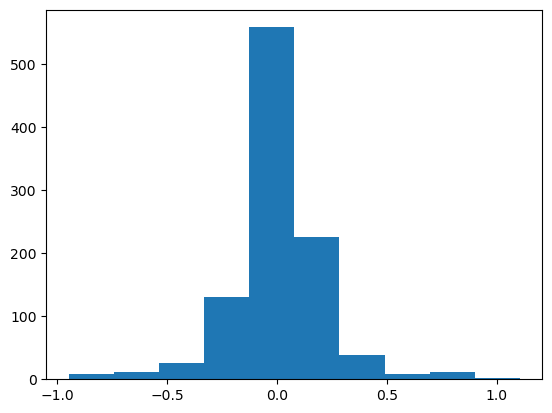

In [30]:
plt.hist(coeffs[1][2].flatten())

(array([147.,  28.,  44.,  35.,  38., 121., 163., 214., 285.,  45.]),
 array([0.12215962, 0.74762994, 1.37310026, 1.99857058, 2.6240409 ,
        3.24951122, 3.87498154, 4.50045186, 5.12592218, 5.7513925 ,
        6.37686282]),
 <BarContainer object of 10 artists>)

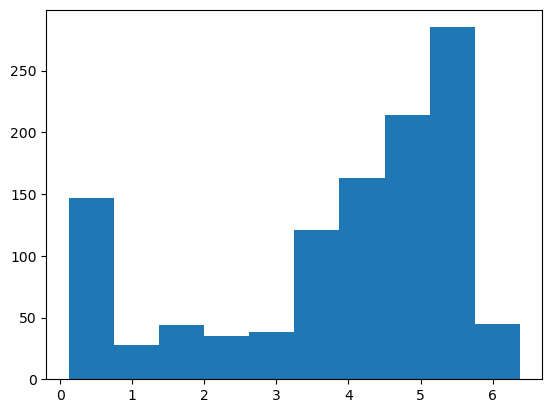

In [31]:
plt.hist( np.hstack([coeffs[0].flatten(), coeffs[0][0].flatten(), coeffs[0][1].flatten(), coeffs[0][2].flatten()]) )

In [ ]:
plt.hist( np.hstack([coeffs[0].flatten(), coeffs[1][0].flatten(), coeffs[1][1].flatten(), coeffs[1][2].flatten()]) )

(array([  12.,   61., 2628.,  484.,  103.,   50.,  105.,  220.,  331.,
         102.]),
 array([-2.44660786, -1.56426079, -0.68191372,  0.20043334,  1.08278041,
         1.96512748,  2.84747455,  3.72982161,  4.61216868,  5.49451575,
         6.37686282]),
 <BarContainer object of 10 artists>)

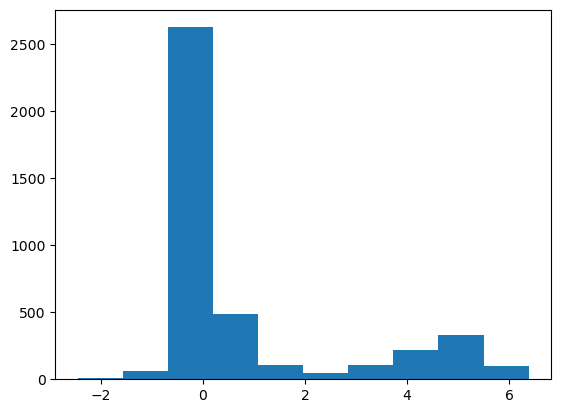

In [32]:
plt.hist( np.hstack([coeffs[0].flatten(), coeffs[1][0].flatten(), coeffs[1][1].flatten(), coeffs[1][2].flatten()]) )

In [33]:
import numpy as np
import pywt
from scipy.sparse.linalg import LinearOperator

# Function to flatten wavelet coefficients into a vector and pad if necessary
def flatten_coeffs(coeffs, original_shape):
    flattened = np.hstack([coeffs[0].flatten()] + [np.hstack([d.flatten() for d in details]) for details in coeffs[1:]])
    # Pad with zeros to match the original size if needed
    original_size = np.prod(original_shape)
    if flattened.size < original_size:
        flattened = np.pad(flattened, (0, original_size - flattened.size), mode='constant')
    return flattened

# Function to restore wavelet coefficients from a flattened vector
def unstack_coeffs(y, coeff_shapes):
    coeffs_restored = []
    idx = 0
    # Restore the approximation coefficients
    cA_shape = coeff_shapes[0]
    cA_size = np.prod(cA_shape)
    cA = y[idx:idx + cA_size].reshape(cA_shape)
    idx += cA_size
    coeffs_restored.append(cA)
    
    # Restore the detail coefficients for each level
    for cH_shape, cV_shape, cD_shape in coeff_shapes[1:]:
        cH_size = np.prod(cH_shape)
        cV_size = np.prod(cV_shape)
        cD_size = np.prod(cD_shape)
        cH = y[idx:idx + cH_size].reshape(cH_shape)
        idx += cH_size
        cV = y[idx:idx + cV_size].reshape(cV_shape)
        idx += cV_size
        cD = y[idx:idx + cD_size].reshape(cD_shape)
        idx += cD_size
        coeffs_restored.append((cH, cV, cD))
    
    return coeffs_restored

# Define the LinearOperator class for the wavelet transform
class WaveletTransformOperator(LinearOperator):
    def __init__(self, image_shape, wavelet='haar', level=3):
        # Initialize the operator with the shape and dtype
        self.image_shape = image_shape
        self.wavelet = wavelet
        self.level = level

        # Perform a wavelet transform to determine the size of the flattened wavelet coefficients
        sample_image = np.zeros(image_shape)
        coeffs = pywt.wavedec2(sample_image, wavelet, level=level)
        self.coeff_shapes = [coeffs[0].shape] + [(d[0].shape, d[1].shape, d[2].shape) for d in coeffs[1:]]
        self.coeff_size = sum(np.prod(shape) for shape in [coeffs[0].shape] + [d[0].shape for d in coeffs[1:]])

        # Define the shape of the operator (image flattened length, image flattened length)
        super().__init__(dtype=np.float64, shape=(np.prod(image_shape), np.prod(image_shape)))

        # Initialize indices for approximation and detail coefficients
        self.approximation_indices, self.detail_indices = self._compute_indices()

    def _compute_indices(self):
        """Compute the indices of approximation and detail coefficients."""
        # Compute the starting index for detail coefficients
        approximation_size = np.prod(self.coeff_shapes[0])

        # Indices for the approximation coefficients (first part of the vector)
        approximation_indices = np.arange(approximation_size)

        # Indices for detail coefficients (everything after the approximation coefficients)
        detail_indices = np.arange(approximation_size, np.prod(self.image_shape))

        return approximation_indices, detail_indices

    def _matvec(self, x):
        """Apply the wavelet transform (A * x)."""
        # Reshape the input vector x to a 2D image
        image = x.reshape(self.image_shape)
        
        # Perform the wavelet transform
        coeffs = pywt.wavedec2(image, self.wavelet, level=self.level)
        
        # Flatten the coefficients into a vector and pad it to match the original size
        return flatten_coeffs(coeffs, self.image_shape)

    def _rmatvec(self, y):
        """Apply the adjoint (inverse wavelet transform, A^T * y)."""
        # Reshape the vector y into wavelet coefficients
        coeffs_restored = unstack_coeffs(y, self.coeff_shapes)
        
        # Perform the inverse wavelet transform
        image_reconstructed = pywt.waverec2(coeffs_restored, self.wavelet)
        
        # Flatten the reconstructed image
        return image_reconstructed.flatten()

# Example usage of the WaveletTransformOperator
image_shape = (256, 256)  # Define the shape of the input image
A = WaveletTransformOperator(image_shape, wavelet='haar', level=3)

# Access the indices for approximation and detail coefficients
approximation_indices = A.approximation_indices
detail_indices = A.detail_indices

print(f"Approximation coefficient indices: {approximation_indices}")
print(f"Detail coefficient indices: {detail_indices}")

# Test the operator with a random image
x = np.random.rand(np.prod(image_shape))  # Flattened image
y = A @ x  # Apply the wavelet transform (A * x)
z = A.T @ y  # Apply the adjoint (A^T * y)

# Verify the adjoint test by checking the inner products
lhs = np.dot(y, y)  # Equivalent to <A x, y>
rhs = np.dot(x, z)  # Equivalent to <x, A^T y>

print(f"<A x, y> = {lhs:.10f}")
print(f"<x, A^T y> = {rhs:.10f}")
print(f"Adjoint test error: {abs(lhs - rhs):.10f}")


Approximation coefficient indices: [   0    1    2 ... 1021 1022 1023]
Detail coefficient indices: [ 1024  1025  1026 ... 65533 65534 65535]
<A x, y> = 21821.0153474529
<x, A^T y> = 21821.0153474529
Adjoint test error: 0.0000000000


In [34]:
%%timeit

_ = pywt.wavedec2(image, 'haar', level=3)

620 µs ± 89.4 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [ ]:
A @ image.flatten()

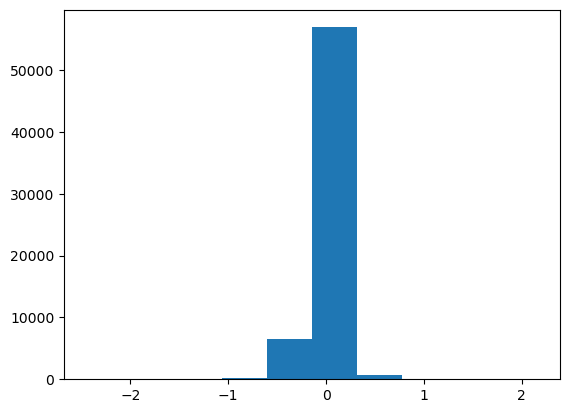

In [37]:
plt.hist((A @ image.flatten())[A.detail_indices])
plt.show()

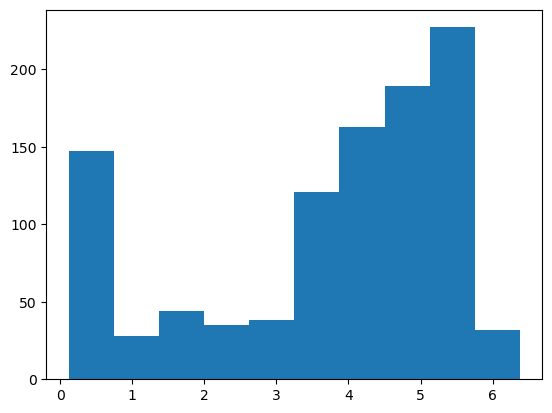

In [39]:
plt.hist((A @ image.flatten())[A.approximation_indices])
plt.show()